# Phần B: Logistic Regression

Mục tiêu: xây dựng mô hình Logistic Regression dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, và so sánh các cách xử lý mất cân bằng lớp.

Quy trình đánh giá (dùng chung với phần Random Forest để so sánh công bằng):

1. Dữ liệu train/test được chia sẵn và dùng chung cả nhóm, test chỉ dùng để báo cáo kết quả cuối.
2. Tuning tham số bằng RandomizedSearchCV, cross-validation 5 fold có stratify, chỉ trên train, chấm điểm theo PR-AUC.
3. Ngưỡng quyết định chọn để F1 lớn nhất trên dự đoán out-of-fold của train, rồi áp dụng sang test.
4. Báo cáo PR-AUC và ROC-AUC (không phụ thuộc ngưỡng) cùng precision, recall, F1 (phụ thuộc ngưỡng).

In [1]:
import json

import pandas as pd
from IPython.display import display

from src.config import ROOT
from src.data import load_train_test
from src.evaluate import evaluate
from src.models import logreg
from src.plots import plot_confusion, plot_importance, plot_pr_curves
from src.tuning import run_experiment, tune

X_train, X_test, y_train, y_test = load_train_test()
print(X_train.shape, X_test.shape)
print(f"Tỷ lệ lớp dương: train {y_train.mean():.4f}, test {y_test.mean():.4f}")

(36168, 33) (9043, 33)
Tỷ lệ lớp dương: train 0.1170, test 0.1170


## 1. Ba mô hình tham chiếu

Logistic Regression là baseline phù hợp vì dễ giải thích (mỗi hệ số cho biết đặc trưng đẩy khả năng đăng ký lên hay xuống) và huấn luyện nhanh. Ta chạy ba biến thể mặc định để đo riêng tác dụng của từng kỹ thuật:

- `logreg_baseline`: mặc định, ngưỡng 0,5.
- `logreg_balanced`: thêm `class_weight="balanced"`, ngưỡng 0,5. Cách này tăng trọng số của lớp ít (khách đăng ký) khi tính loss để mô hình không bỏ qua lớp này.
- `logreg_baseline_thr`: giống baseline nhưng chọn lại ngưỡng. Dòng này tách riêng tác dụng của việc đổi ngưỡng.

In [2]:
baseline, _ = run_experiment("logreg_baseline", logreg.build(), X_train, y_train, X_test, y_test, tune_threshold=False)
balanced, _ = run_experiment("logreg_balanced", logreg.build(class_weight="balanced"), X_train, y_train, X_test, y_test, tune_threshold=False)
baseline_thr, _ = run_experiment("logreg_baseline_thr", logreg.build(), X_train, y_train, X_test, y_test, tune_threshold=True)
results = pd.read_csv(ROOT / "reports/results/results.csv")
display(results[results["model"].str.startswith("logreg")].set_index("model").round(3))

,accuracy,precision,recall,f1,pr_auc,roc_auc,threshold,cv_pr_auc
model,,,,,,,,
logreg_tuned,0.834,0.343,0.454,0.390,0.365,0.756,0.178,0.371
logreg_smote_tuned,0.834,0.337,0.430,0.378,0.348,0.742,0.591,0.346
logreg_baseline,0.893,0.673,0.167,0.268,0.365,0.756,0.500,NaN
logreg_balanced,0.703,0.232,0.668,0.345,0.364,0.755,0.500,NaN
logreg_baseline_thr,0.835,0.344,0.453,0.391,0.365,0.756,0.178,NaN


## 2. Tuning tham số

Không gian tìm kiếm gồm `C` (nghịch đảo của độ mạnh regularization, lấy theo thang log từ 0,001 đến 100) và có dùng `class_weight="balanced"` hay không. Mô hình dùng phạt `l2` mặc định, tức là thu nhỏ các trọng số để tránh học thuộc nhiễu; `C` càng nhỏ thì phạt càng mạnh. Dùng RandomizedSearchCV với 25 tổ hợp để tiết kiệm thời gian so với duyệt hết lưới. Chấm điểm bằng PR-AUC vì chỉ 11,7% mẫu là lớp dương, trong khi accuracy bị lấn át bởi lớp âm.

In [3]:
search = tune(logreg.build(), logreg.search_space(), X_train, y_train, n_iter=25)
print("Tham số tốt nhất:", search.best_params_)
print(f"PR-AUC trung bình trên cross-validation: {search.best_score_:.4f}")
tuned, _ = run_experiment("logreg_tuned", search.best_estimator_, X_train, y_train, X_test, y_test, extra={"cv_pr_auc": search.best_score_})
with open(ROOT / "reports/results/logreg_best_params.json", "w", encoding="utf-8") as file:
    json.dump(search.best_params_, file, default=str, indent=2)

Tham số tốt nhất: {'C': np.float64(0.0745934328572655), 'class_weight': None}
PR-AUC trung bình trên cross-validation: 0.3708


## 3. Tuning kết hợp SMOTE

SMOTE sinh thêm mẫu lớp dương tổng hợp để cân bằng tỷ lệ lớp. Nó được đặt trong `imblearn.pipeline.Pipeline` nên khi cross-validation, SMOTE chỉ chạy trên phần train của từng fold và fold kiểm tra giữ nguyên phân phối thật. Nếu áp dụng SMOTE lên cả train trước khi chia fold, các mẫu tổng hợp sẽ rò rỉ sang fold kiểm tra và điểm cross-validation bị thổi phồng.

In [4]:
search_smote = tune(logreg.build_smote(), logreg.search_space_smote(), X_train, y_train, n_iter=15)
print("Tham số tốt nhất:", search_smote.best_params_)
print(f"PR-AUC trung bình trên cross-validation: {search_smote.best_score_:.4f}")
smote_tuned, _ = run_experiment("logreg_smote_tuned", search_smote.best_estimator_, X_train, y_train, X_test, y_test, extra={"cv_pr_auc": search_smote.best_score_})

Tham số tốt nhất: {'clf__C': np.float64(0.0019517224641449498)}
PR-AUC trung bình trên cross-validation: 0.3459


## 4. Kết quả trên tập test

In [5]:
results = pd.read_csv(ROOT / "reports/results/results.csv")
display(results[results["model"].str.startswith("logreg")].set_index("model").round(3))

,accuracy,precision,recall,f1,pr_auc,roc_auc,threshold,cv_pr_auc
model,,,,,,,,
logreg_baseline,0.893,0.673,0.167,0.268,0.365,0.756,0.500,NaN
logreg_balanced,0.703,0.232,0.668,0.345,0.364,0.755,0.500,NaN
logreg_baseline_thr,0.835,0.344,0.453,0.391,0.365,0.756,0.178,NaN
logreg_tuned,0.843,0.357,0.431,0.391,0.366,0.756,0.185,0.371
logreg_smote_tuned,0.834,0.337,0.430,0.378,0.348,0.742,0.591,0.346


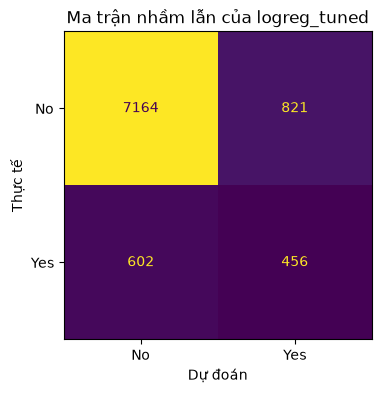

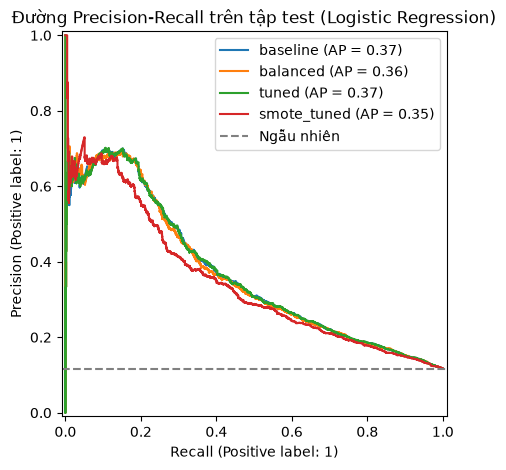

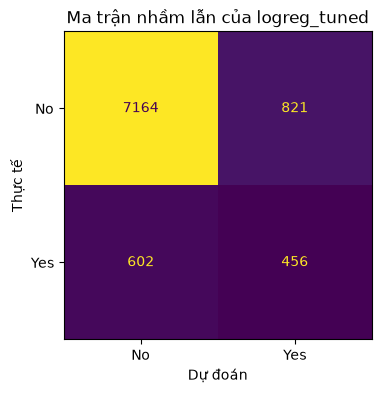

In [6]:
models = {"baseline": baseline, "balanced": balanced, "tuned": tuned, "smote_tuned": smote_tuned}
plot_pr_curves(models, X_test, y_test, "Đường Precision-Recall trên tập test (Logistic Regression)", "logreg_pr_curves.png")
threshold = results.loc[results["model"] == "logreg_tuned", "threshold"].iloc[0]
plot_confusion(tuned, X_test, y_test, threshold, "Ma trận nhầm lẫn của logreg_tuned", "logreg_confusion.png")

## 5. Đặc trưng nào quan trọng

,contact_unknown,poutcome_failure,poutcome_unknown,housing,poutcome_other,marital_married,loan,job_housemaid,campaign,job_blue-collar,...,job_unemployed,pdays,previous,contact_telephone,education,contact_cellular,balance,job_student,job_retired,poutcome_success
hệ số,-0.854,-0.817,-0.791,-0.59,-0.485,-0.425,-0.416,-0.341,-0.288,-0.237,...,-0.011,0.0,0.011,0.018,0.071,0.133,0.215,0.349,0.461,1.391


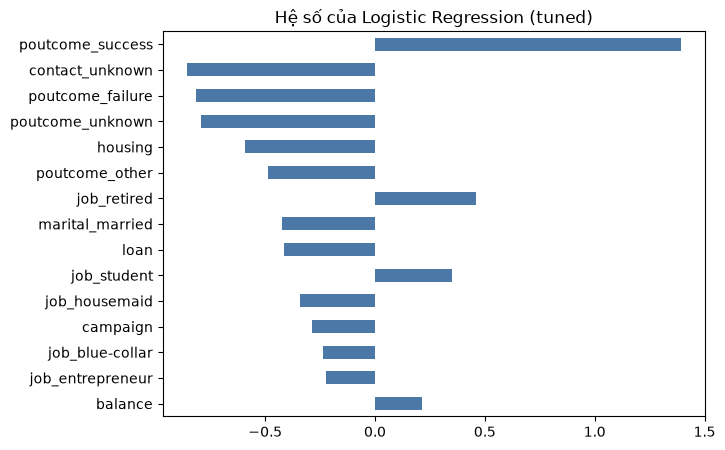

In [7]:
coefficients = pd.Series(tuned.coef_[0], index=X_train.columns)
plot_importance(coefficients, "Hệ số của Logistic Regression (tuned)", "logreg_coefficients.png")
display(coefficients.sort_values().round(3).to_frame("hệ số").T)

## 6. Nhận xét

Kết quả trên tập test (11,7% mẫu là lớp dương):

- Đổi ngưỡng quyết định là thay đổi hiệu quả nhất. Với ngưỡng 0,5, mô hình mặc định chỉ bắt được 16,7% khách sẽ đăng ký (recall) và F1 là 0,268. Chọn lại ngưỡng khoảng 0,18 đưa F1 lên 0,391 mà PR-AUC không đổi (0,365). Nghĩa là chất lượng xếp hạng của mô hình giữ nguyên, ta chỉ chọn điểm vận hành tốt hơn trên cùng một đường Precision-Recall.
- `class_weight="balanced"` cho tác dụng gần giống đổi ngưỡng: recall tăng lên 0,668 nhưng precision tụt còn 0,232, và PR-AUC gần như không đổi (0,364). Cách này chỉ dịch điểm vận hành, không tạo ra mô hình xếp hạng tốt hơn.
- Tuning `C` và `class_weight` gần như không thay đổi gì (PR-AUC 0,3658 so với 0,3652). Tuning chọn `C` khoảng 0,07, tức phạt mạnh hơn mặc định nhưng điểm xếp hạng vẫn gần như cũ. Điều này cho thấy giới hạn nằm ở bản thân mô hình tuyến tính với các đặc trưng hiện có, không phải ở tham số.
- SMOTE không giúp ích: PR-AUC giảm xuống 0,348 và F1 là 0,378, thấp hơn mô hình không dùng SMOTE.
- Về diễn giải, `poutcome_success` (lần chiến dịch trước thành công) là yếu tố tăng khả năng đăng ký mạnh nhất, tiếp theo là khách đã nghỉ hưu hoặc là sinh viên. Các yếu tố làm giảm mạnh là không rõ kênh liên lạc (`contact_unknown`), kết quả chiến dịch trước thất bại hoặc không rõ, và có khoản vay nhà (`housing`).

Logistic Regression đạt F1 khoảng 0,39 và là mốc tham chiếu để so sánh với Random Forest ở phần C.